# Phase 7 F1 learning-rate mini-sweep on Kaggle

This self-contained notebook runs the two declared full-data learning-rate experiments in one Kaggle session: `5e-6` and `2e-5`. The completed `1e-5` F1 run remains the reference and is not retrained.

Both new runs start independently from the pinned `neurlang/ipa-whisper-base` checkpoint. They use the frozen 3,629-clip training set, the same 732-clip validation set, effective batch 8, and the selected validation decoding policy with repetition penalty `1.08`. The sealed test set is not attached or read.


## Kaggle inputs and session settings

Enable a **T4 GPU** and **Internet**. Attach exactly two private datasets:

1. The full training bundle with `bundle_type=phase7_f1_train_v1` (3,629 clips, 10.851637 hours).
2. The validation bundle with `bundle_type=phase5_validation_baseline` (732 clips).

Do not attach the test bundle, an F1 checkpoint, the master manifest, or raw project data. This notebook contains the trainer, analysis, plots, and ZIP packaging; no separate Python runner is required.


## Embedded validated trainer

This cell defines the same lazy-feature, FP16 AMP, resumable F1 trainer used previously. It does not begin training. The learning-rate run cells below call it with separate output directories.


In [1]:
"""Phase F1 full fine-tuning on the frozen Nyishi Narration split.

This is a private Kaggle runner. It starts from the pinned pretrained model,
uses lazy CPU feature extraction (no multi-gigabyte feature cache), trains with
FP16 AMP and gradient accumulation, validates with the Phase 6C-equivalent
batch-8 greedy policy, and saves resumable epoch checkpoints. It never reads
the test split.
"""
from __future__ import annotations

import argparse
import copy
import csv
import gc
import hashlib
import json
import math
import random
import re
import time
import unicodedata
import zipfile
from pathlib import Path

import numpy as np
import soundfile as sf
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import (
    GenerationConfig,
    WhisperForConditionalGeneration,
    WhisperProcessor,
    get_linear_schedule_with_warmup,
)


MODEL_ID = "neurlang/ipa-whisper-base"
MODEL_REVISION = "949f7c4e4ee374b5202bc5886f6e4552e5ae2371"
EOS_ID = 50257
MAX_LENGTH = 448
EXPECTED_TRAIN = 3629
EXPECTED_VALIDATION = 732
EXPECTED_REFERENCE_CODEPOINTS = 64137


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def safe(root: Path, relative: str) -> Path:
    path = (root / relative).resolve()
    path.relative_to(root.resolve())
    return path


def extract_bundle(archive: Path, bundle_type: str, destination: Path) -> tuple[Path, dict]:
    if archive.is_dir():
        marker = archive / "bundle_record.json"
        return archive, json.loads(marker.read_text())
    with zipfile.ZipFile(archive) as zf:
        markers = [n for n in zf.namelist() if n.endswith("bundle_record.json")]
        matches = [(n, json.loads(zf.read(n))) for n in markers]
        matches = [(n, r) for n, r in matches if r.get("bundle_type") == bundle_type]
        assert len(matches) == 1, f"Expected one {bundle_type} marker in {archive}"
        marker_name, record = matches[0]
        root = destination / bundle_type
        root.mkdir(parents=True, exist_ok=True)
        for member in tqdm(zf.infolist(), desc=f"Extracting {bundle_type}", unit="file"):
            target = (root / member.filename).resolve()
            target.relative_to(root.resolve())
        for member in tqdm(zf.infolist(), desc=f"Writing {bundle_type}", unit="file"):
            zf.extract(member, root)
        return (root / Path(marker_name).parent).resolve(), record


def discover_bundle(root: Path, bundle_type: str) -> Path:
    candidates = []
    for marker in root.rglob("bundle_record.json"):
        try:
            if json.loads(marker.read_text()).get("bundle_type") == bundle_type:
                candidates.append(marker.parent)
        except (OSError, json.JSONDecodeError):
            pass
    for archive in root.rglob("*.zip"):
        try:
            with zipfile.ZipFile(archive) as zf:
                for name in zf.namelist():
                    if name.endswith("bundle_record.json") and json.loads(zf.read(name)).get("bundle_type") == bundle_type:
                        candidates.append(archive)
        except (OSError, zipfile.BadZipFile, json.JSONDecodeError):
            pass
    candidates = sorted(set(candidates))
    assert len(candidates) == 1, f"Expected one {bundle_type} input, found {len(candidates)}: {candidates}"
    return candidates[0]


def verify_bundle(root: Path, record: dict, expected_partition: str) -> None:
    sums = root / "SHA256SUMS.txt"
    if sums.exists():
        entries = [line.split("  ", 1) for line in sums.read_text().splitlines() if line]
        for expected, relative in tqdm(entries, desc="Verifying bundle checksums", unit="file"):
            assert sha256(safe(root, relative)) == expected, f"Checksum failed: {relative}"
    # Validation bundles declare evaluation_partition/contains_test_audio;
    # the full F1 training bundle declares contains_validation_or_test_audio.
    # Accept either explicit schema without weakening the split checks.
    if "evaluation_partition" in record:
        assert record["evaluation_partition"] == expected_partition
    if "contains_test_audio" in record:
        assert record["contains_test_audio"] is False
    if "contains_validation_or_test_audio" in record:
        assert record["contains_validation_or_test_audio"] is False


def normalize(value: str) -> str:
    return re.sub(r" {2,}", " ", unicodedata.normalize("NFD", str(value)).strip())


def edit_counts(reference: str, hypothesis: str) -> tuple[int, int, int]:
    ref, hyp = list(reference), list(hypothesis)
    distance = [[0] * (len(hyp) + 1) for _ in range(len(ref) + 1)]
    for i in range(len(ref) + 1):
        distance[i][0] = i
    for j in range(len(hyp) + 1):
        distance[0][j] = j
    for i in range(1, len(ref) + 1):
        for j in range(1, len(hyp) + 1):
            distance[i][j] = min(
                distance[i - 1][j] + 1,
                distance[i][j - 1] + 1,
                distance[i - 1][j - 1] + (ref[i - 1] != hyp[j - 1]),
            )
    substitutions = deletions = insertions = 0
    i, j = len(ref), len(hyp)
    while i or j:
        if i and j and ref[i - 1] == hyp[j - 1] and distance[i][j] == distance[i - 1][j - 1]:
            i, j = i - 1, j - 1
        elif i and j and distance[i][j] == distance[i - 1][j - 1] + 1:
            substitutions += 1; i, j = i - 1, j - 1
        elif i and distance[i][j] == distance[i - 1][j] + 1:
            deletions += 1; i -= 1
        else:
            insertions += 1; j -= 1
    return substitutions, deletions, insertions


def main(argv: list[str] | None = None) -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--train-input", type=Path)
    parser.add_argument("--validation-input", type=Path)
    parser.add_argument("--output", type=Path, default=Path("/kaggle/working/phase7_F1_private"))
    parser.add_argument("--resume", type=Path, default=None, help="epoch_N directory from this exact F1 run")
    parser.add_argument("--physical-batch", type=int, default=2)
    parser.add_argument("--accumulation", type=int, default=4)
    parser.add_argument("--validation-batch", type=int, default=8)
    parser.add_argument("--max-epochs", type=int, default=10)
    parser.add_argument("--patience", type=int, default=3)
    parser.add_argument("--learning-rate", type=float, default=1e-5)
    parser.add_argument("--repetition-penalty", type=float, default=1.0)
    parser.add_argument("--weight-decay", type=float, default=0.01)
    parser.add_argument("--seed", type=int, default=0)
    args, unknown = parser.parse_known_args(argv)
    if argv is not None and unknown:
        raise ValueError(f"Unknown arguments: {unknown}")
    assert torch.cuda.is_available(), "A CUDA GPU is required."
    assert args.physical_batch * args.accumulation == 8
    assert args.validation_batch == 8
    input_root = Path("/kaggle/input")
    if args.train_input is None:
        args.train_input = discover_bundle(input_root, "phase7_f1_train_v1")
    if args.validation_input is None:
        args.validation_input = discover_bundle(input_root, "phase5_validation_baseline")
    args.output.mkdir(parents=True, exist_ok=True)
    extracted = args.output / "_extracted_inputs"
    train_root, train_record = extract_bundle(args.train_input, "phase7_f1_train_v1", extracted)
    val_root, val_record = extract_bundle(args.validation_input, "phase5_validation_baseline", extracted)
    verify_bundle(train_root, train_record, "train")
    verify_bundle(val_root, val_record, "validation")
    assert train_record["clips"] == EXPECTED_TRAIN and val_record["clips"] == EXPECTED_VALIDATION
    assert train_record.get("contains_validation_or_test_audio") is False

    with (train_root / "train_manifest.csv").open(newline="", encoding="utf-8") as stream:
        train_rows = list(csv.DictReader(stream))
    with (val_root / "validation_manifest.csv").open(newline="", encoding="utf-8") as stream:
        val_rows = list(csv.DictReader(stream))
    assert len(train_rows) == EXPECTED_TRAIN and len(val_rows) == EXPECTED_VALIDATION
    assert sum(len(normalize(row["reference"])) for row in val_rows) == EXPECTED_REFERENCE_CODEPOINTS
    assert {row["sample_id"] for row in train_rows}.isdisjoint({row["sample_id"] for row in val_rows})

    random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed); torch.cuda.manual_seed_all(args.seed)
    processor = WhisperProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    generation_config = GenerationConfig.from_dict(json.loads((val_root / "generation_config.json").read_text()))
    # Reproduce the corrected Phase 7 validation policy. Only the explicitly
    # declared repetition penalty may differ between matched experiments.
    generation_config.max_new_tokens = None
    generation_config.do_sample = False
    generation_config.num_beams = 1
    generation_config.num_return_sequences = 1
    generation_config.no_repeat_ngram_size = 0
    generation_config.suppress_tokens = []
    generation_config.forced_decoder_ids = None
    generation_config.language = None
    generation_config.task = "transcribe"
    generation_config.return_timestamps = False
    generation_config.max_length = MAX_LENGTH
    generation_config.begin_suppress_tokens = [220, EOS_ID]
    generation_config.return_dict_in_generate = True
    generation_config.output_scores = False
    generation_config.pad_token_id = EOS_ID
    generation_config.eos_token_id = EOS_ID
    generation_config.repetition_penalty = args.repetition_penalty
    assert generation_config.eos_token_id == EOS_ID and generation_config.max_length == MAX_LENGTH
    assert generation_config.decoder_start_token_id == 50258
    assert generation_config.forced_decoder_ids is None
    assert generation_config.language is None and generation_config.task == "transcribe"
    assert generation_config.no_repeat_ngram_size == 0

    def read_audio(root: Path, row: dict) -> np.ndarray:
        path = safe(root, row["audio_file"])
        audio, sample_rate = sf.read(path, dtype="float32", always_2d=True)
        assert sample_rate == 16000 and audio.shape[1] == 1
        assert 0.5 <= len(audio) / sample_rate < 30
        return audio[:, 0]

    def make_features(
        root: Path,
        rows: list[dict],
        *,
        return_attention_mask: bool = False,
    ) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
        audios = [read_audio(root, row) for row in rows]
        # Force Whisper's fixed 30-second window for batched inputs. Plain
        # padding=True pads only to the longest item in this batch and can
        # return a time axis different from the required 3,000 frames.
        packed = processor.feature_extractor(
            audios,
            sampling_rate=16000,
            return_tensors="pt",
            return_attention_mask=return_attention_mask,
            padding="max_length",
            truncation=True,
            max_length=480000,
        )
        features = packed.input_features
        if features.ndim == 2:
            features = features.unsqueeze(0)
        assert features.ndim == 3 and features.shape[1] == 80, (
            f"Unexpected Whisper feature shape before window normalization: {tuple(features.shape)}"
        )
        # Defensive normalization for minor Transformers/feature-extractor
        # patch differences: the model contract is always 80 x 3000.
        if features.shape[-1] > 3000:
            features = features[..., :3000]
        elif features.shape[-1] < 3000:
            features = F.pad(features, (0, 3000 - features.shape[-1]))
        assert tuple(features.shape[1:]) == (80, 3000)
        assert torch.isfinite(features).all().item(), "Non-finite Whisper features"
        features = features.to(dtype=torch.float32)
        if not return_attention_mask:
            return features
        attention_mask = packed.attention_mask
        if attention_mask.ndim == 1:
            attention_mask = attention_mask.unsqueeze(0)
        if attention_mask.shape[-1] > 3000:
            attention_mask = attention_mask[..., :3000]
        elif attention_mask.shape[-1] < 3000:
            attention_mask = F.pad(attention_mask, (0, 3000 - attention_mask.shape[-1]))
        assert tuple(attention_mask.shape) == (len(rows), 3000)
        return features, attention_mask.long()

    def make_labels(rows: list[dict]) -> torch.Tensor:
        # Use WhisperTokenizerFast.__call__ for batched tokenization. This
        # avoids the fast-tokenizer warning caused by encode-then-pad.
        references = [normalize(row["reference"]) for row in rows]
        encoded = processor.tokenizer(
            references,
            add_special_tokens=False,
            padding=True,
            return_tensors="pt",
        )
        token_lengths = encoded["attention_mask"].sum(dim=1).tolist()
        # Add one column so every example retains an explicit EOS token.
        input_ids = F.pad(encoded["input_ids"], (0, 1), value=processor.tokenizer.pad_token_id)
        attention_mask = F.pad(encoded["attention_mask"], (0, 1), value=0)
        for row_index, (reference, token_length) in enumerate(zip(references, token_lengths)):
            ids = encoded["input_ids"][row_index, :token_length].tolist()
            assert processor.tokenizer.decode(ids, skip_special_tokens=False) == reference
            assert token_length + 1 < MAX_LENGTH
            input_ids[row_index, token_length] = EOS_ID
            attention_mask[row_index, token_length] = 1
        labels = input_ids.masked_fill(attention_mask.ne(1), -100)
        for row_index, token_length in enumerate(token_lengths):
            assert labels[row_index, token_length].item() == EOS_ID
        return labels

    device = torch.device("cuda:0")
    model_source = args.resume / "model" if args.resume else MODEL_ID
    model_kwargs = {"dtype": torch.float32, "attn_implementation": "sdpa"}
    if not args.resume:
        model_kwargs["revision"] = MODEL_REVISION
    model = WhisperForConditionalGeneration.from_pretrained(model_source, **model_kwargs).to(device).train()
    model.config.use_cache = False
    decay, no_decay = [], []
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            (no_decay if name.endswith("bias") or "layer_norm" in name.lower() else decay).append(parameter)
    optimizer = torch.optim.AdamW(
        [{"params": decay, "weight_decay": args.weight_decay}, {"params": no_decay, "weight_decay": 0.0}],
        lr=args.learning_rate,
    )
    micro_batches = math.ceil(len(train_rows) / args.physical_batch)
    steps_per_epoch = math.ceil(micro_batches / args.accumulation)
    total_steps = steps_per_epoch * args.max_epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, max(1, math.ceil(0.05 * total_steps)), total_steps)
    scaler = torch.amp.GradScaler("cuda", init_scale=256.0)
    fingerprint = hashlib.sha256(json.dumps({
        "model": MODEL_ID, "revision": MODEL_REVISION, "train": train_record.get("manifest_sha256"),
        "validation": val_record.get("manifest_sha256"), "seed": args.seed,
        "physical_batch": args.physical_batch, "accumulation": args.accumulation,
        "validation_batch": args.validation_batch, "max_epochs": args.max_epochs,
        "patience": args.patience, "learning_rate": args.learning_rate,
        "generation": generation_config.to_dict(),
    }, sort_keys=True, default=str).encode()).hexdigest()
    start_epoch = 0; completed_steps = 0; history = []; best_cer = float("inf"); best_epoch = None; stale_epochs = 0
    if args.resume:
        state = torch.load(args.resume / "training_state.pt", map_location="cpu", weights_only=False)
        assert state["fingerprint"] == fingerprint and state["epoch"] < args.max_epochs
        optimizer.load_state_dict(state["optimizer"]); scheduler.load_state_dict(state["scheduler"]); scaler.load_state_dict(state["scaler"])
        for item in optimizer.state.values():
            for key, value in item.items():
                if isinstance(value, torch.Tensor): item[key] = value.to(device)
        random.setstate(state["python_rng"]); np.random.set_state(state["numpy_rng"]); torch.set_rng_state(state["torch_rng"]); torch.cuda.set_rng_state_all(state["cuda_rng"])
        start_epoch = state["epoch"]; completed_steps = state["completed_steps"]; history = state["history"]; best_cer = state["best_cer"]; best_epoch = state["best_epoch"]; stale_epochs = state.get("stale_epochs", 0)
    print({"train_clips": len(train_rows), "validation_clips": len(val_rows), "steps_per_epoch": steps_per_epoch, "max_epochs": args.max_epochs, "patience": args.patience, "fingerprint": fingerprint})

    def evaluate(epoch: int) -> tuple[dict, list[dict]]:
        model.eval(); model.config.use_cache = True; records = []; started = time.perf_counter()
        for begin in tqdm(range(0, len(val_rows), args.validation_batch), desc=f"Epoch {epoch} validation", unit="batch"):
            rows = val_rows[begin:begin + args.validation_batch]
            features, attention_mask = make_features(
                val_root, rows, return_attention_mask=True
            )
            features = features.to(device)
            attention_mask = attention_mask.to(device)
            with torch.inference_mode():
                generated = model.generate(
                    input_features=features,
                    attention_mask=attention_mask,
                    generation_config=copy.deepcopy(generation_config),
                )
            for row, sequence in zip(rows, generated.sequences.detach().cpu().tolist()):
                ids = sequence[:sequence.index(EOS_ID) + 1] if EOS_ID in sequence else sequence[:MAX_LENGTH]
                raw = processor.tokenizer.decode(ids, skip_special_tokens=True); hypothesis = normalize(raw); reference = normalize(row["reference"])
                substitutions, deletions, insertions = edit_counts(reference, hypothesis)
                records.append({"sample_id": row["sample_id"], "reference": reference, "raw_prediction": raw, "normalized_prediction": hypothesis, "token_ids": ids, "eos": bool(ids and ids[-1] == EOS_ID), "cap_without_eos": len(ids) >= MAX_LENGTH and (not ids or ids[-1] != EOS_ID), "S": substitutions, "D": deletions, "I": insertions, "duration_seconds": float(row["duration_seconds"])})
            del features, attention_mask, generated
        model.train(); model.config.use_cache = False; gc.collect(); torch.cuda.empty_cache()
        reference_codepoints = sum(len(r["reference"]) for r in records); S = sum(r["S"] for r in records); D = sum(r["D"] for r in records); I = sum(r["I"] for r in records)
        return {"clips": len(records), "reference_codepoints": reference_codepoints, "S": S, "D": D, "I": I, "edit_count": S + D + I, "corpus_cer": (S + D + I) / reference_codepoints, "eos_count": sum(r["eos"] for r in records), "cap_without_eos": sum(r["cap_without_eos"] for r in records), "replacement_character_outputs": sum("�" in r["normalized_prediction"] for r in records), "elapsed_seconds": time.perf_counter() - started}, records

    run_started = time.perf_counter(); torch.cuda.reset_peak_memory_stats(device)
    for epoch in range(start_epoch + 1, args.max_epochs + 1):
        model.train(); model.config.use_cache = False; indices = list(range(len(train_rows))); random.shuffle(indices); groups = [indices[i:i + args.physical_batch] for i in range(0, len(indices), args.physical_batch)]; losses = []; epoch_updates = 0; amp_retries = 0; epoch_started = time.perf_counter()
        for begin in tqdm(range(0, len(groups), args.accumulation), desc=f"Epoch {epoch} training", unit="update"):
            accumulation_groups = groups[begin:begin + args.accumulation]
            for attempt in range(8):
                optimizer.zero_grad(set_to_none=True); finite = True; group_losses = []
                try:
                    for group in accumulation_groups:
                        rows = [train_rows[i] for i in group]; features = make_features(train_root, rows).to(device); labels = make_labels(rows).to(device)
                        with torch.autocast(device_type="cuda", dtype=torch.float16): loss = model(input_features=features, labels=labels).loss
                        if not torch.isfinite(loss).item(): raise FloatingPointError("nonfinite forward loss")
                        group_losses.append(float(loss.detach())); scaler.scale(loss / len(accumulation_groups)).backward(); del features, labels
                    scaler.unscale_(optimizer); grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True, foreach=False); assert float(grad_norm) > 0
                    old_scale = scaler.get_scale(); scaler.step(optimizer); scaler.update()
                    if scaler.get_scale() < old_scale: amp_retries += 1; continue
                    scheduler.step(); completed_steps += 1; epoch_updates += 1; losses.extend(group_losses); break
                except torch.cuda.OutOfMemoryError as exc:
                    torch.cuda.empty_cache(); raise RuntimeError("CUDA OOM. Restart with --physical-batch 1 --accumulation 8; do not change the effective batch size.") from exc
            else: raise RuntimeError("No finite AMP update after eight attempts.")
        train_memory = torch.cuda.max_memory_allocated(device) / 1024**2
        validation, predictions = evaluate(epoch)
        improved = validation["corpus_cer"] < best_cer
        if improved: best_cer = validation["corpus_cer"]; best_epoch = epoch; stale_epochs = 0
        else: stale_epochs += 1
        record = {"epoch": epoch, "updates": epoch_updates, "cumulative_updates": completed_steps, "training_loss": sum(losses) / len(losses), "amp_retries": amp_retries, "train_peak_allocated_mib": train_memory, "epoch_seconds": time.perf_counter() - epoch_started, "validation": validation}
        history.append(record); checkpoint = args.output / f"epoch_{epoch:02d}"; checkpoint.mkdir(exist_ok=True); model.save_pretrained(checkpoint / "model", safe_serialization=True); torch.save({"fingerprint": fingerprint, "epoch": epoch, "completed_steps": completed_steps, "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "python_rng": random.getstate(), "numpy_rng": np.random.get_state(), "torch_rng": torch.get_rng_state(), "cuda_rng": torch.cuda.get_rng_state_all(), "history": history, "best_cer": best_cer, "best_epoch": best_epoch, "stale_epochs": stale_epochs}, checkpoint / "training_state.pt")
        (args.output / f"validation_epoch_{epoch:02d}_private.jsonl").write_text("\n".join(json.dumps(p, ensure_ascii=False) for p in predictions) + "\n")
        (args.output / "aggregate_history.json").write_text(json.dumps(history, indent=2) + "\n")
        print({"epoch": epoch, "validation_cer_percent": 100 * validation["corpus_cer"], "best_epoch": best_epoch, "stale_epochs": stale_epochs, "train_peak_allocated_mib": train_memory, "validation_seconds": validation["elapsed_seconds"]})
        if stale_epochs >= args.patience: print(f"Early stopping after {args.patience} non-improving validation epochs."); break
    report = {"experiment": "F1", "status": "complete", "model_id": MODEL_ID, "model_revision": MODEL_REVISION, "train_clips": len(train_rows), "train_hours": train_record["hours"], "validation_clips": len(val_rows), "validation_hours": val_record["hours"], "test_data_used": False, "seed": args.seed, "physical_batch": args.physical_batch, "accumulation": args.accumulation, "effective_batch": 8, "validation_batch": args.validation_batch, "learning_rate": args.learning_rate, "repetition_penalty": args.repetition_penalty, "weight_decay": args.weight_decay, "max_epochs": args.max_epochs, "patience": args.patience, "best_epoch": best_epoch, "best_validation_cer": best_cer, "completed_steps": completed_steps, "total_wall_seconds": time.perf_counter() - run_started, "peak_allocated_mib": torch.cuda.max_memory_allocated(device) / 1024**2, "peak_reserved_mib": torch.cuda.max_memory_reserved(device) / 1024**2, "history": history}
    (args.output / "F1_report_private.json").write_text(json.dumps(report, indent=2) + "\n"); print("F1 complete; best epoch", best_epoch, "CER", 100 * best_cer)


## Preflight and resume helper

This cell discovers bundle markers rather than relying on Kaggle dataset names. If a run was interrupted, rerunning its cell resumes from the latest completed epoch. Work from an interrupted partial epoch is repeated.


In [2]:
# Discover and verify the two attached private bundles before training.
from pathlib import Path
import json
import shutil

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path("/kaggle/working/phase7_F1_LR_private")
TRAIN_INPUT = discover_bundle(INPUT_ROOT, "phase7_f1_train_v1")
VALIDATION_INPUT = discover_bundle(INPUT_ROOT, "phase5_validation_baseline")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print({
    "train_input": str(TRAIN_INPUT),
    "validation_input": str(VALIDATION_INPUT),
    "output_root": str(OUTPUT_ROOT),
    "free_working_GiB": round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2),
    "test_bundle_attached_or_used": False,
})

def run_or_resume_rate(learning_rate: float) -> dict:
    """Run one LR experiment or resume from its latest completed epoch."""
    label = f"lr_{learning_rate:.0e}".replace("-", "m")
    output = OUTPUT_ROOT / label
    report_path = output / "F1_report_private.json"
    if report_path.is_file():
        report = json.loads(report_path.read_text())
        assert report["status"] == "complete"
        assert report["test_data_used"] is False
        assert abs(report["learning_rate"] - learning_rate) < 1e-15
        assert abs(report["repetition_penalty"] - 1.08) < 1e-12
        print(f"{label} is already complete; training was not repeated.")
        return report

    checkpoints = sorted(
        path for path in output.glob("epoch_*")
        if (path / "training_state.pt").is_file() and (path / "model" / "config.json").is_file()
    ) if output.exists() else []
    arguments = [
        "--train-input", str(TRAIN_INPUT),
        "--validation-input", str(VALIDATION_INPUT),
        "--output", str(output),
        "--physical-batch", "2",
        "--accumulation", "4",
        "--validation-batch", "8",
        "--max-epochs", "10",
        "--patience", "3",
        "--learning-rate", str(learning_rate),
        "--repetition-penalty", "1.08",
        "--weight-decay", "0.01",
        "--seed", "0",
    ]
    if checkpoints:
        arguments += ["--resume", str(checkpoints[-1])]
        print("Resuming from:", checkpoints[-1])
    else:
        print(f"Starting {label} independently from the pinned pretrained checkpoint.")

    main(arguments)
    report = json.loads(report_path.read_text())
    assert report["status"] == "complete" and report["test_data_used"] is False
    assert abs(report["learning_rate"] - learning_rate) < 1e-15
    assert abs(report["repetition_penalty"] - 1.08) < 1e-12
    gc.collect()
    torch.cuda.empty_cache()
    return report


{'train_input': '/kaggle/input/datasets/kanchanpotdar/phase-7-f1-train-bundle/phase7_f1_train_bundle', 'validation_input': '/kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle', 'output_root': '/kaggle/working/phase7_F1_LR_private', 'free_working_GiB': 19.5, 'test_bundle_attached_or_used': False}


## Run 1 — learning rate 5e-6

This is an independent run from the original pinned pretrained checkpoint. Maximum 10 epochs; early stopping after three non-improving validation checks.


In [3]:
# Run 1 of 2: lower learning rate.
# Safe to rerun: it skips a completed run or resumes from the latest completed epoch.
report_5e6 = run_or_resume_rate(5e-6)
print({
    "learning_rate": report_5e6["learning_rate"],
    "best_epoch": report_5e6["best_epoch"],
    "best_validation_CER_percent": 100 * report_5e6["best_validation_cer"],
})


Starting lr_5em06 independently from the pinned pretrained checkpoint.


Verifying bundle checksums:   0%|          | 0/3631 [00:00<?, ?file/s]

Verifying bundle checksums:   0%|          | 0/737 [00:00<?, ?file/s]

preprocessor_config.json:   0%|          | 0.00/356 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.23k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

... (32 outputs left out)

Epoch 6 training:   0%|          | 0/454 [00:00<?, ?update/s]

Epoch 6 validation:   0%|          | 0/92 [00:00<?, ?batch/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'epoch': 6, 'validation_cer_percent': 53.699112836584185, 'best_epoch': 3, 'stale_epochs': 3, 'train_peak_allocated_mib': 2189.646484375, 'validation_seconds': 187.50302849599984}
Early stopping after 3 non-improving validation epochs.
F1 complete; best epoch 3 CER 51.05477337574255
{'learning_rate': 5e-06, 'best_epoch': 3, 'best_validation_CER_percent': 51.05477337574255}


## Run 2 — learning rate 2e-5

Run this after the first experiment finishes. It uses the same frozen data order policy and evaluation contract but a separate model initialization and output directory.


In [4]:
# Run 2 of 2: higher learning rate.
# Safe to rerun: it skips a completed run or resumes from the latest completed epoch.
report_2e5 = run_or_resume_rate(2e-5)
print({
    "learning_rate": report_2e5["learning_rate"],
    "best_epoch": report_2e5["best_epoch"],
    "best_validation_CER_percent": 100 * report_2e5["best_validation_cer"],
})


Starting lr_2em05 independently from the pinned pretrained checkpoint.


Verifying bundle checksums:   0%|          | 0/3631 [00:00<?, ?file/s]

Verifying bundle checksums:   0%|          | 0/737 [00:00<?, ?file/s]

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

{'train_clips': 3629, 'validation_clips': 732, 'steps_per_epoch': 454, 'max_epochs': 10, 'patience': 3, 'fingerprint': '7d6419b425485d0109709f2af0432c51f489c25c0fb2a1910df3520093bd7277'}


Epoch 1 training:   0%|          | 0/454 [00:00<?, ?update/s]

... (27 outputs left out)

Epoch 8 training:   0%|          | 0/454 [00:00<?, ?update/s]

Epoch 8 validation:   0%|          | 0/92 [00:00<?, ?batch/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'epoch': 8, 'validation_cer_percent': 49.9540047086705, 'best_epoch': 5, 'stale_epochs': 3, 'train_peak_allocated_mib': 2190.63330078125, 'validation_seconds': 178.65863397900011}
Early stopping after 3 non-improving validation epochs.
F1 complete; best epoch 5 CER 47.23950293902116
{'learning_rate': 2e-05, 'best_epoch': 5, 'best_validation_CER_percent': 47.23950293902116}


## Aggregate analysis and validation-only selection

The following cells compare both new runs with the completed `1e-5` reference. The reference point uses its selected Epoch 3 checkpoint re-decoded at repetition penalty `1.08` (48.39172% CER). Test data remain sealed.


In [5]:
# Load both completed reports and build matched epoch and best-checkpoint tables.
import json
import numpy as np
import pandas as pd
from IPython.display import display

REFERENCE = {
    "run": "1e-5 reference",
    "learning_rate": 1e-5,
    "best_epoch": 3,
    "best_CER_percent": 48.391723965885525,
    "S": 14542,
    "D": 5739,
    "I": 10756,
    "EOS_count": 732,
    "cap_without_EOS": 0,
    "training_loss": 0.9269547315442693,
    "peak_MiB": 3558.43017578125,
    "runtime_minutes": 38.47080035361667,
}

reports = {}
epoch_rows = []
for label, rate in [("5e-6", 5e-6), ("2e-5", 2e-5)]:
    out = OUTPUT_ROOT / f"lr_{rate:.0e}".replace("-", "m")
    report = json.loads((out / "F1_report_private.json").read_text())
    assert report["status"] == "complete" and report["test_data_used"] is False
    assert report["train_clips"] == 3629 and report["validation_clips"] == 732
    assert abs(report["repetition_penalty"] - 1.08) < 1e-12
    reports[label] = report
    for item in report["history"]:
        val = item["validation"]
        epoch_rows.append({
            "run": label,
            "learning_rate": rate,
            "epoch": item["epoch"],
            "training_loss": item["training_loss"],
            "validation_CER_percent": 100 * val["corpus_cer"],
            "S": val["S"], "D": val["D"], "I": val["I"],
            "EOS_count": val["eos_count"],
            "cap_without_EOS": val["cap_without_eos"],
            "U+FFFD": val["replacement_character_outputs"],
            "epoch_minutes": item["epoch_seconds"] / 60,
            "validation_minutes": val["elapsed_seconds"] / 60,
            "peak_MiB": item["train_peak_allocated_mib"],
        })
epoch_table = pd.DataFrame(epoch_rows)

summary_rows = []
for label, report in reports.items():
    best_epoch = int(report["best_epoch"])
    best_item = next(item for item in report["history"] if item["epoch"] == best_epoch)
    val = best_item["validation"]
    summary_rows.append({
        "run": label,
        "learning_rate": report["learning_rate"],
        "best_epoch": best_epoch,
        "best_CER_percent": 100 * report["best_validation_cer"],
        "S": val["S"], "D": val["D"], "I": val["I"],
        "EOS_count": val["eos_count"],
        "cap_without_EOS": val["cap_without_eos"],
        "peak_MiB": report["peak_allocated_mib"],
        "runtime_minutes": sum(item["epoch_seconds"] for item in report["history"]) / 60,
    })
summary_rows.append(REFERENCE)
summary_table = pd.DataFrame(summary_rows).sort_values("learning_rate").reset_index(drop=True)
display(epoch_table.round(4))
display(summary_table.round(4))

winner = summary_table.loc[summary_table["best_CER_percent"].idxmin()].to_dict()
print("Validation-only winner:", winner["run"], "CER", round(winner["best_CER_percent"], 5), "%")
print("The sealed test set remains untouched; this table is for validation selection only.")


,run,learning_rate,epoch,training_loss,validation_CER_percent,S,D,I,EOS_count,cap_without_EOS,U+FFFD,epoch_minutes,validation_minutes,peak_MiB
0,5e-6,0.0,1,2.8174,54.3867,16751,4316,13815,731,1,1,6.3027,3.1783,2189.6465
1,5e-6,0.0,2,1.3990,52.1400,15326,5771,12344,732,0,0,6.0686,3.0375,2189.6465
2,5e-6,0.0,3,1.1458,51.0548,15212,5021,12512,732,0,0,6.0651,3.0462,2189.6465
3,5e-6,0.0,4,1.0114,53.2735,15615,5109,13444,732,0,0,6.1505,3.1291,2189.6465
4,5e-6,0.0,5,0.8880,51.0938,15156,4798,12816,731,1,0,6.0857,3.0595,2189.6465
5,5e-6,0.0,6,0.8057,53.6991,15469,5950,13022,731,1,0,6.1613,3.1251,2189.6465
6,2e-5,0.0,1,2.1545,55.7666,14391,8485,12891,732,0,0,6.0327,2.9741,2189.6099
7,2e-5,0.0,2,1.0427,48.7082,14099,6498,10643,732,0,0,5.9691,2.9110,2189.6099
8,2e-5,0.0,3,0.7448,48.3044,14708,5095,11178,732,0,0,5.9999,2.9446,2189.6099
9,2e-5,0.0,4,0.5472,48.5180,14643,6419,10056,732,0,1,6.0082,2.9698,2189.6099


,run,learning_rate,best_epoch,best_CER_percent,S,D,I,EOS_count,cap_without_EOS,peak_MiB,runtime_minutes,training_loss
0,5e-6,0.0,3,51.0548,15212,5021,12512,732,0,2189.6465,36.8339,NaN
1,1e-5 reference,0.0,3,48.3917,14542,5739,10756,732,0,3558.4302,38.4708,0.927
2,2e-5,0.0,5,47.2395,14503,5583,10212,732,0,2190.6333,48.0045,NaN


Validation-only winner: 2e-5 CER 47.2395 %
The sealed test set remains untouched; this table is for validation selection only.


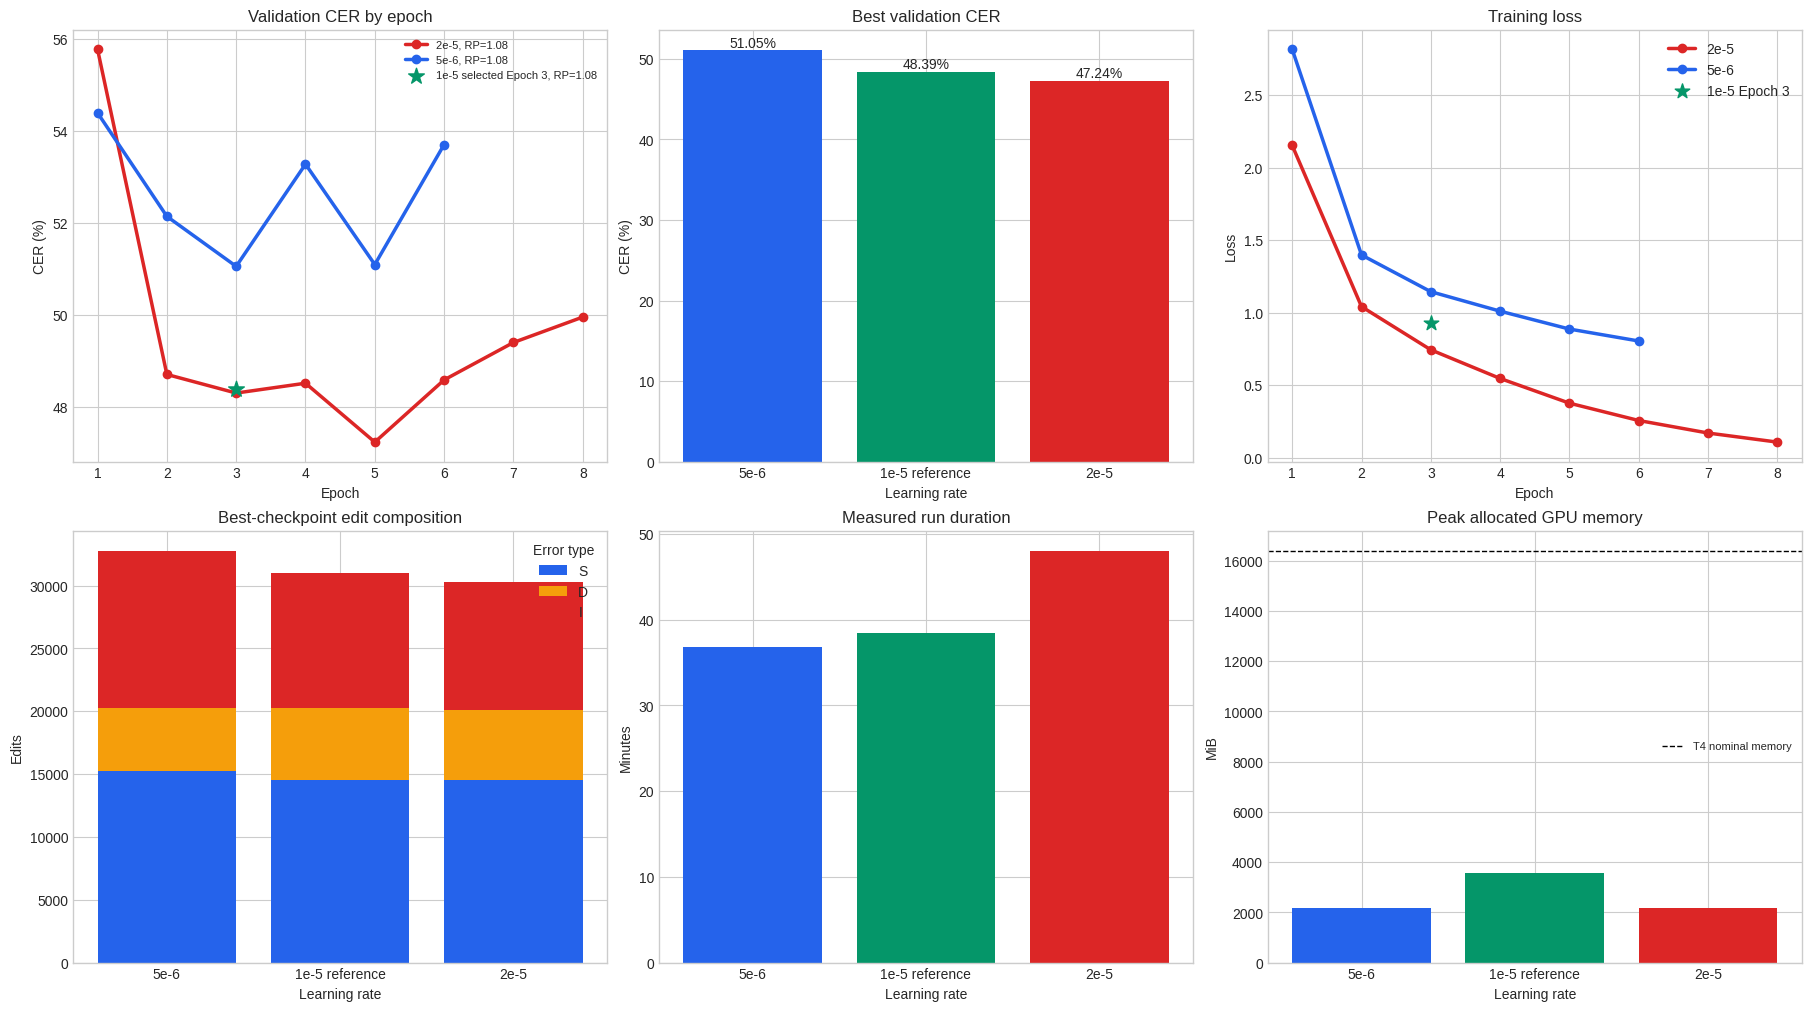

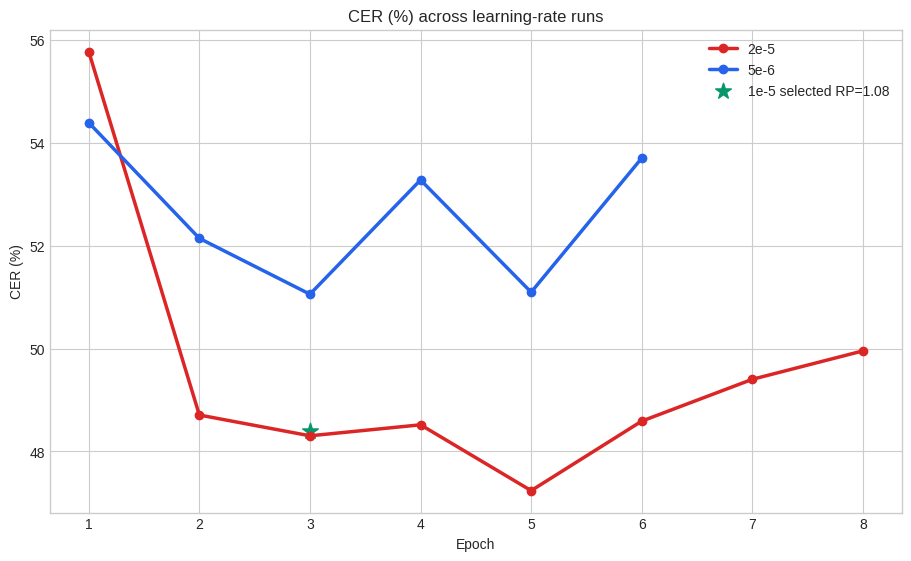

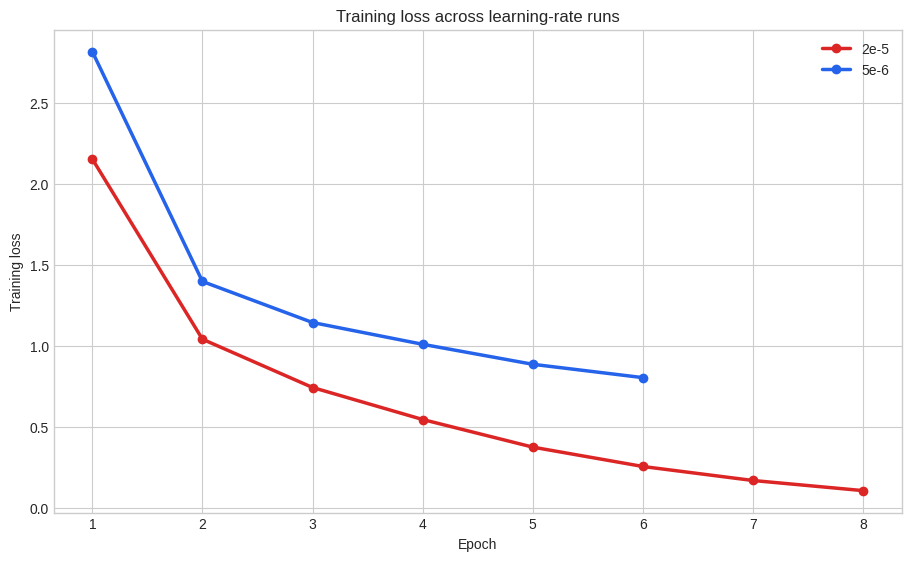

Saved plots and aggregate tables to /kaggle/working/phase7_F1_LR_private/comparison_plots


In [6]:
# Create and save comparison plots for quality, errors, runtime, and memory.
import matplotlib.pyplot as plt

PLOT_DIR = OUTPUT_ROOT / "comparison_plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")
colors = {"5e-6": "#2563eb", "2e-5": "#dc2626"}

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
for label, group in epoch_table.groupby("run"):
    axes[0, 0].plot(group["epoch"], group["validation_CER_percent"], "o-", lw=2.5,
                    color=colors[label], label=f"{label}, RP=1.08")
axes[0, 0].scatter([REFERENCE["best_epoch"]], [REFERENCE["best_CER_percent"]], s=140,
                   marker="*", color="#059669", label="1e-5 selected Epoch 3, RP=1.08", zorder=5)
axes[0, 0].set(title="Validation CER by epoch", xlabel="Epoch", ylabel="CER (%)")
axes[0, 0].legend(fontsize=8)

bars = summary_table.sort_values("learning_rate")
bar_colors = [colors.get(run, "#059669") for run in bars["run"]]
axes[0, 1].bar(bars["run"], bars["best_CER_percent"], color=bar_colors)
axes[0, 1].set(title="Best validation CER", xlabel="Learning rate", ylabel="CER (%)")
for i, value in enumerate(bars["best_CER_percent"]):
    axes[0, 1].text(i, value + 0.4, f"{value:.2f}%", ha="center")

for label, group in epoch_table.groupby("run"):
    axes[0, 2].plot(group["epoch"], group["training_loss"], "o-", lw=2.5,
                    color=colors[label], label=label)
axes[0, 2].scatter([REFERENCE["best_epoch"]], [REFERENCE["training_loss"]], s=120,
                   marker="*", color="#059669", label="1e-5 Epoch 3")
axes[0, 2].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
axes[0, 2].legend()

bottom = np.zeros(len(bars))
for metric, color in [("S", "#2563eb"), ("D", "#f59e0b"), ("I", "#dc2626")]:
    values = bars[metric].to_numpy()
    axes[1, 0].bar(bars["run"], values, bottom=bottom, color=color, label=metric)
    bottom += values
axes[1, 0].set(title="Best-checkpoint edit composition", xlabel="Learning rate", ylabel="Edits")
axes[1, 0].legend(title="Error type")

axes[1, 1].bar(bars["run"], bars["runtime_minutes"], color=bar_colors)
axes[1, 1].set(title="Measured run duration", xlabel="Learning rate", ylabel="Minutes")

axes[1, 2].bar(bars["run"], bars["peak_MiB"], color=bar_colors)
axes[1, 2].axhline(16 * 1024, color="black", ls="--", lw=1, label="T4 nominal memory")
axes[1, 2].set(title="Peak allocated GPU memory", xlabel="Learning rate", ylabel="MiB")
axes[1, 2].legend(fontsize=8)

figure_path = PLOT_DIR / "lr_sweep_comparison_dashboard.png"
fig.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()

# Save separate publication-friendly plots as well.
for column, ylabel, filename in [
    ("validation_CER_percent", "CER (%)", "cer_curves.png"),
    ("training_loss", "Training loss", "training_loss_curves.png"),
]:
    fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
    for label, group in epoch_table.groupby("run"):
        ax.plot(group["epoch"], group[column], "o-", lw=2.5, color=colors[label], label=label)
    if column == "validation_CER_percent":
        ax.scatter([REFERENCE["best_epoch"]], [REFERENCE["best_CER_percent"]], s=140,
                   marker="*", color="#059669", label="1e-5 selected RP=1.08")
    ax.set(xlabel="Epoch", ylabel=ylabel, title=ylabel + " across learning-rate runs")
    ax.legend()
    fig.savefig(PLOT_DIR / filename, dpi=220, bbox_inches="tight")
    plt.show()

epoch_table.to_csv(PLOT_DIR / "lr_sweep_epoch_metrics.csv", index=False)
summary_table.to_csv(PLOT_DIR / "lr_sweep_best_summary.csv", index=False)
print("Saved plots and aggregate tables to", PLOT_DIR)


## Save downloadable ZIP files

The results ZIP contains reports, epoch histories, private validation predictions, aggregate tables, plots, and checksums. Each new run also receives a separate best-checkpoint ZIP. This avoids one oversized archive containing every intermediate checkpoint.


In [7]:
# Create one results ZIP plus one best-checkpoint ZIP for each new learning rate.
# Intermediate epoch checkpoints stay in /kaggle/working for resume but are not
# duplicated into a multi-gigabyte archive.
import hashlib
import zipfile
from IPython.display import FileLink, display
from tqdm.auto import tqdm

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

results_zip = Path("/kaggle/working/phase7_F1_LR_sweep_results_private.zip")
result_files = sorted(PLOT_DIR.rglob("*"))
for label, rate in [("5e-6", 5e-6), ("2e-5", 2e-5)]:
    out = OUTPUT_ROOT / f"lr_{rate:.0e}".replace("-", "m")
    result_files += [out / "F1_report_private.json", out / "aggregate_history.json"]
    result_files += sorted(out.glob("validation_epoch_*_private.jsonl"))
result_files = sorted({path for path in result_files if path.is_file()})

checksums = []
with zipfile.ZipFile(results_zip, "w", zipfile.ZIP_DEFLATED, compresslevel=6, allowZip64=True) as archive:
    for path in tqdm(result_files, desc="Zipping LR results", unit="file"):
        relative = path.relative_to(OUTPUT_ROOT).as_posix()
        archive.write(path, f"phase7_F1_LR_sweep/{relative}")
        checksums.append(f"{sha256_file(path)}  phase7_F1_LR_sweep/{relative}")
    archive.writestr("phase7_F1_LR_sweep/SHA256SUMS.txt", "\n".join(checksums) + "\n")

checkpoint_zips = []
for label, report in reports.items():
    rate = float(report["learning_rate"])
    out = OUTPUT_ROOT / f"lr_{rate:.0e}".replace("-", "m")
    best_dir = out / f"epoch_{int(report['best_epoch']):02d}"
    assert (best_dir / "model" / "config.json").is_file()
    assert (best_dir / "training_state.pt").is_file()
    destination = Path(f"/kaggle/working/phase7_F1_LR_{label.replace('-', 'm')}_best_checkpoint_private.zip")
    with zipfile.ZipFile(destination, "w", zipfile.ZIP_STORED, allowZip64=True) as archive:
        files = [path for path in best_dir.rglob("*") if path.is_file()]
        for path in tqdm(files, desc=f"Zipping {label} best checkpoint", unit="file"):
            archive.write(path, f"phase7_F1_LR_{label}_best_checkpoint/{path.relative_to(best_dir).as_posix()}")
    checkpoint_zips.append(destination)

for archive in [results_zip, *checkpoint_zips]:
    assert zipfile.ZipFile(archive).testzip() is None
    print(archive.name, round(archive.stat().st_size / 1024**2, 2), "MiB")
    display(FileLink(str(archive)))

print("Download all three ZIPs before ending the Kaggle session.")


Zipping LR results:   0%|          | 0/23 [00:00<?, ?file/s]

Zipping 5e-6 best checkpoint:   0%|          | 0/4 [00:00<?, ?file/s]

Zipping 2e-5 best checkpoint:   0%|          | 0/4 [00:00<?, ?file/s]

phase7_F1_LR_sweep_results_private.zip 2.54 MiB


/kaggle/working/phase7_F1_LR_sweep_results_private.zip

phase7_F1_LR_5em6_best_checkpoint_private.zip 831.02 MiB


/kaggle/working/phase7_F1_LR_5em6_best_checkpoint_private.zip

phase7_F1_LR_2em5_best_checkpoint_private.zip 831.02 MiB


/kaggle/working/phase7_F1_LR_2em5_best_checkpoint_private.zip

Download all three ZIPs before ending the Kaggle session.


## What to do after download

Keep all three ZIPs private and download the executed notebook with outputs. Compare the three learning rates using minimum validation CER, S/D/I counts, generation health, runtime, and memory. Then run the independently initialized LoRA comparison using the selected full-fine-tuning learning rate. Do not open the sealed 683-clip test set until the validation-only model and decoding configuration have been locked.
